# 06 — MobileNetV2 Model Development
**Retinopathy Detection System**

Trains MobileNetV2 and evaluates it using the exact train/validation split saved from Notebook 05.

- Use the Python 3.11.7 virtual environment.
- The saved split CSVs must exist in `S:/ISP/data/processed/results`.
- MobileNetV2 requires its own `preprocess_input` (pixel range converted to approximately -1 to +1).
- Validation metrics are calculated on the labelled validation split, not the unlabelled public test set.

## 1. Imports and reproducibility

In [1]:
import os, sys, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]
TensorFlow: 2.16.1
GPU: []


## 2. Paths and dataset discovery

In [2]:
PROJECT_ROOT = Path(r"S:\ISP")
DATA_ROOT = PROJECT_ROOT / "data"
MODEL_DIR = DATA_ROOT / "processed" / "models"
RESULT_DIR = DATA_ROOT / "processed" / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_SPLIT = RESULT_DIR / "efficientnetb3_train_split.csv"
VAL_SPLIT = RESULT_DIR / "efficientnetb3_validation_split.csv"
if not TRAIN_SPLIT.exists() or not VAL_SPLIT.exists():
    raise FileNotFoundError("Split CSVs missing. Save them first from Notebook 05.")

csvs = [p for p in (DATA_ROOT / "raw").rglob("train.csv") if "aptos" in str(p).lower()]
if not csvs:
    raise FileNotFoundError("APTOS train.csv not found under S:/ISP/data/raw.")
DATASET_DIR = csvs[0].parent
IMAGE_DIR = DATASET_DIR / "train_images"
if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image folder missing: {IMAGE_DIR}")

print("Dataset:", DATASET_DIR)
print("Images:", IMAGE_DIR)
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)

Dataset: S:\ISP\data\raw\aptos\aptos2019-blindness-detection
Images: S:\ISP\data\raw\aptos\aptos2019-blindness-detection\train_images
Models: S:\ISP\data\processed\models
Results: S:\ISP\data\processed\results


## 3. Load and validate the same split from Notebook 05

In [3]:
train_df = pd.read_csv(TRAIN_SPLIT)
val_df = pd.read_csv(VAL_SPLIT)
for frame in (train_df, val_df):
    frame["id_code"] = frame["id_code"].astype(str)
    frame["diagnosis"] = pd.to_numeric(frame["diagnosis"]).astype(int)
    frame["image_path"] = frame["id_code"].apply(lambda x: str(IMAGE_DIR / f"{x}.png"))

missing_train = train_df.loc[~train_df.image_path.apply(os.path.isfile), "image_path"]
missing_val = val_df.loc[~val_df.image_path.apply(os.path.isfile), "image_path"]
if len(missing_train) or len(missing_val):
    raise FileNotFoundError(f"Missing images: train={len(missing_train)}, val={len(missing_val)}")
if set(train_df.id_code) & set(val_df.id_code):
    raise ValueError("Train/validation split overlap detected.")
if not train_df.diagnosis.between(0, 4).all() or not val_df.diagnosis.between(0, 4).all():
    raise ValueError("Expected five labels: 0, 1, 2, 3, 4.")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
display(train_df.diagnosis.value_counts().sort_index().to_frame("train_count"))
display(val_df.diagnosis.value_counts().sort_index().to_frame("validation_count"))

Training images: 2929
Validation images: 733


,train_count
diagnosis,
0,1444
1,296
2,799
3,154
4,236


,validation_count
diagnosis,
0,361
1,74
2,200
3,39
4,59


## 4. MobileNetV2 preprocessing and tf.data pipeline

In [4]:
IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 5
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame.image_path.values, frame.diagnosis.values.astype(np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, yb.shape)
print("Preprocessed range:", float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))

Batch: (16, 224, 224, 3) (16,)
Preprocessed range: -1.0 1.0


## 5. Preview training images

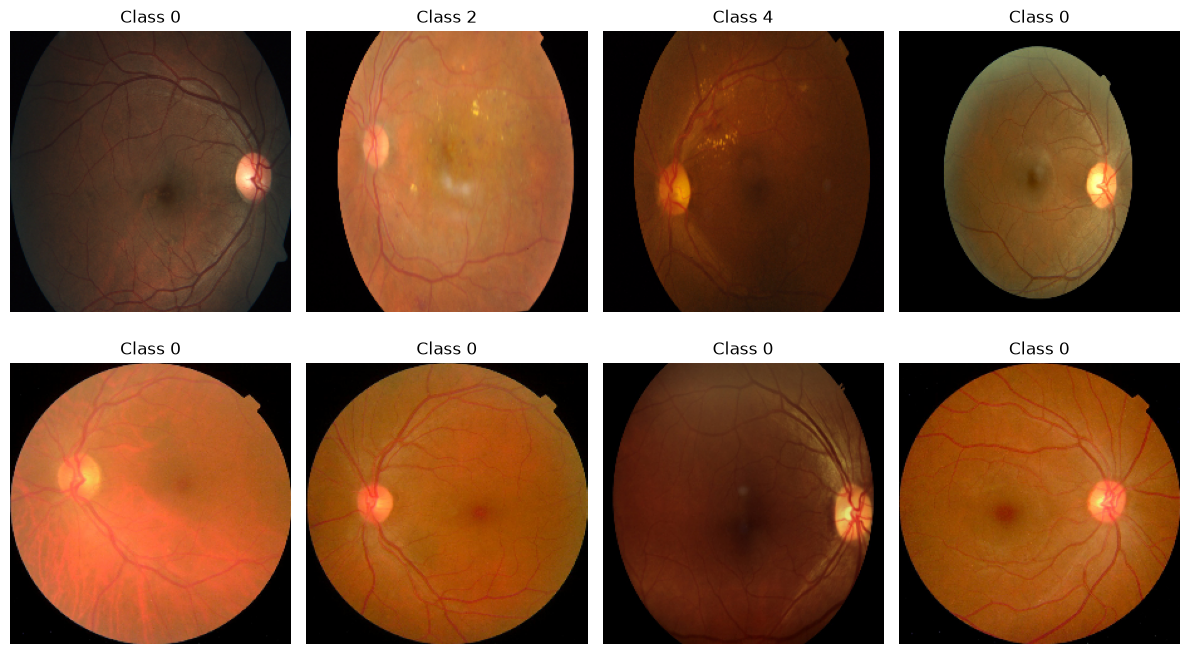

In [5]:
plt.figure(figsize=(12, 7))
for x, y in train_ds.take(1):
    view = (x + 1.0) * 127.5
    for i in range(min(8, len(x))):
        plt.subplot(2, 4, i+1)
        plt.imshow(tf.cast(tf.clip_by_value(view[i], 0, 255), tf.uint8).numpy())
        plt.title(f"Class {int(y[i])}"); plt.axis("off")
plt.tight_layout(); plt.show()

## 6. Class weights

In [6]:
class_ids = np.arange(NUM_CLASSES)
weights = compute_class_weight("balanced", classes=class_ids,
                               y=train_df.diagnosis.values)
class_weights = {int(k): float(v) for k, v in zip(class_ids, weights)}
print(class_weights)

{0: 0.4056786703601108, 1: 1.979054054054054, 2: 0.7331664580725907, 3: 3.803896103896104, 4: 2.4822033898305085}


## 7. Build MobileNetV2

In [7]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.06)
], name="augmentation")

base_model = tf.keras.applications.MobileNetV2(
    include_top=False, weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs, name="mobilenetv2_retinopathy")
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_retinopathy"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,509 (8.66 MB)

 Trainable params: 8,965 (35.02 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 8. Train classification head

In [8]:
STAGE1_EPOCHS = 5
stage1_path = MODEL_DIR / "mobilenetv2_stage1_best.keras"
callbacks1 = [
    tf.keras.callbacks.ModelCheckpoint(stage1_path, monitor="val_loss",
                                       save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                         patience=1, min_lr=1e-6, verbose=1)
]
history_stage1 = model.fit(train_ds, validation_data=val_ds,
    epochs=STAGE1_EPOCHS, class_weight=class_weights, callbacks=callbacks1)
pd.DataFrame(history_stage1.history).to_csv(
    RESULT_DIR / "mobilenetv2_stage1_history.csv", index=False)

Epoch 1/5
183/184 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.5605 - loss: 1.5799
Epoch 1: val_loss improved from None to 0.91690, saving model to S:\ISP\data\processed\models\mobilenetv2_stage1_best.keras

Epoch 1: finished saving model to S:\ISP\data\processed\models\mobilenetv2_stage1_best.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 146s 760ms/step - accuracy: 0.5606 - loss: 1.5796 - val_accuracy: 0.6262 - val_loss: 0.9169 - learning_rate: 0.0010
Epoch 2/5
183/184 ━━━━━━━━━━━━━━━━━━━━ 0s 615ms/step - accuracy: 0.6506 - loss: 1.2484
Epoch 2: val_loss improved from 0.91690 to 0.82871, saving model to S:\ISP\data\processed\models\mobilenetv2_stage1_best.keras

Epoch 2: finished saving model to S:\ISP\data\processed\models\mobilenetv2_stage1_best.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 139s 755ms/step - accuracy: 0.6504 - loss: 1.2495 - val_accuracy: 0.6808 - val_loss: 0.8287 - learning_rate: 0.0010
Epoch 3/5
183/184 ━━━━━━━━━━━━━━━━━━━━ 4s 5s/step - accuracy: 0.6783 - loss: 1.1615
Epoch 3: val_

## 9. Fine-tune upper layers

In [9]:
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.70)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
FINETUNE_EPOCHS = 5
FINAL_MODEL_PATH = MODEL_DIR / "mobilenetv2_final.keras"
callbacks2 = [
    tf.keras.callbacks.ModelCheckpoint(FINAL_MODEL_PATH, monitor="val_loss",
                                       save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                         patience=1, min_lr=1e-7, verbose=1)
]
history_finetune = model.fit(train_ds, validation_data=val_ds,
    epochs=FINETUNE_EPOCHS, class_weight=class_weights, callbacks=callbacks2)
pd.DataFrame(history_finetune.history).to_csv(
    RESULT_DIR / "mobilenetv2_finetuning_history.csv", index=False)
if not FINAL_MODEL_PATH.exists():
    model.save(FINAL_MODEL_PATH)
print("Saved model:", FINAL_MODEL_PATH)

Epoch 1/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 683ms/step - accuracy: 0.6890 - loss: 1.0637
Epoch 1: val_loss improved from None to 0.82495, saving model to S:\ISP\data\processed\models\mobilenetv2_final.keras

Epoch 1: finished saving model to S:\ISP\data\processed\models\mobilenetv2_final.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 162s 836ms/step - accuracy: 0.6890 - loss: 1.0637 - val_accuracy: 0.6658 - val_loss: 0.8249 - learning_rate: 1.0000e-05
Epoch 2/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 712ms/step - accuracy: 0.7002 - loss: 0.9800
Epoch 2: val_loss did not improve from 0.82495

Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
184/184 ━━━━━━━━━━━━━━━━━━━━ 158s 858ms/step - accuracy: 0.7002 - loss: 0.9800 - val_accuracy: 0.6426 - val_loss: 0.9678 - learning_rate: 1.0000e-05
Epoch 3/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 692ms/step - accuracy: 0.7200 - loss: 0.8790
Epoch 3: val_loss did not improve from 0.82495

Epoch 3: ReduceLROnPlateau reducing learning rate to 8.9999996

## 10. Training curves

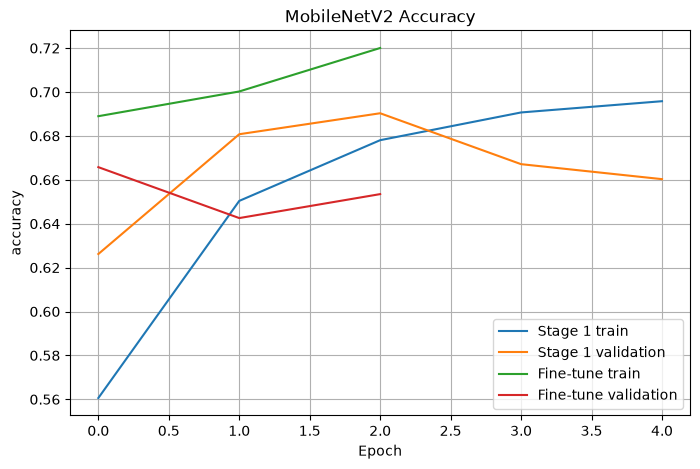

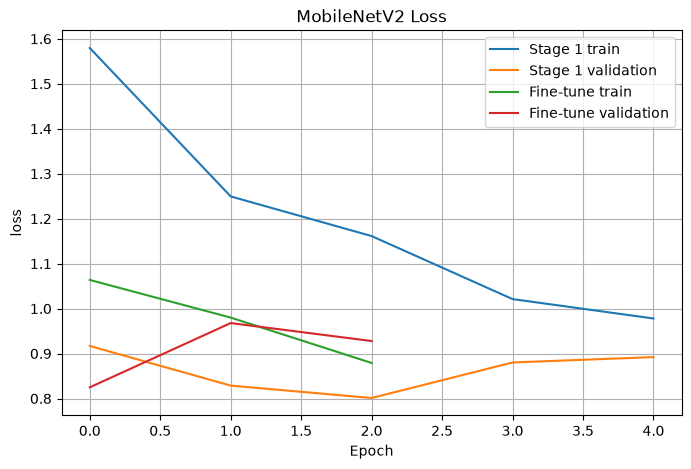

In [10]:
def plot_history(histories, metric, title):
    plt.figure(figsize=(8, 5))
    for label, h in histories:
        if metric in h.history:
            plt.plot(h.history[metric], label=f"{label} train")
        if "val_"+metric in h.history:
            plt.plot(h.history["val_"+metric], label=f"{label} validation")
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel(metric)
    plt.grid(True); plt.legend(); plt.show()

plot_history([("Stage 1", history_stage1), ("Fine-tune", history_finetune)],
             "accuracy", "MobileNetV2 Accuracy")
plot_history([("Stage 1", history_stage1), ("Fine-tune", history_finetune)],
             "loss", "MobileNetV2 Loss")

## 11. Load best model and predict validation data

In [11]:
model = tf.keras.models.load_model(FINAL_MODEL_PATH)
y_true = val_df.diagnosis.to_numpy(dtype=int)
y_prob = model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)
assert len(y_true) == len(y_pred) == len(y_prob)
print("Actual:", y_true.shape, "| Predicted:", y_pred.shape,
      "| Probabilities:", y_prob.shape)

46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 571ms/step
Actual: (733,) | Predicted: (733,) | Probabilities: (733, 5)


## 12. Calculate metrics and save JSON

In [12]:
accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
metrics = {
    "accuracy": float(accuracy),
    "macro_precision": float(precision_macro),
    "macro_recall": float(recall_macro),
    "macro_f1": float(f1_macro),
    "quadratic_weighted_kappa": float(qwk),
    "validation_images": int(len(y_true)),
    "validation_split_source": "Notebook 05 saved split",
    "image_size": IMG_SIZE
}
print(json.dumps(metrics, indent=4))
with open(RESULT_DIR / "mobilenetv2_validation_results.json", "w") as f:
    json.dump(metrics, f, indent=4)

{
    "accuracy": 0.6657571623465212,
    "macro_precision": 0.49914912313198984,
    "macro_recall": 0.5395778273551408,
    "macro_f1": 0.49246519798763727,
    "quadratic_weighted_kappa": 0.7698676417961345,
    "validation_images": 733,
    "validation_split_source": "Notebook 05 saved split",
    "image_size": 224
}


## 13. Classification report

In [13]:
report = classification_report(y_true, y_pred, labels=[0,1,2,3,4],
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))
report_df.to_csv(RESULT_DIR / "mobilenetv2_classification_report.csv")

,precision,recall,f1-score,support
0,0.9440,0.9335,0.9387,361.0000
1,0.3621,0.5676,0.4421,74.0000
2,0.6832,0.3450,0.4585,200.0000
3,0.2326,0.5128,0.3200,39.0000
4,0.2740,0.3390,0.3030,59.0000
accuracy,0.6658,0.6658,0.6658,0.6658
macro avg,0.4991,0.5396,0.4925,733.0000
weighted avg,0.7223,0.6658,0.6735,733.0000


## 14. Confusion matrix

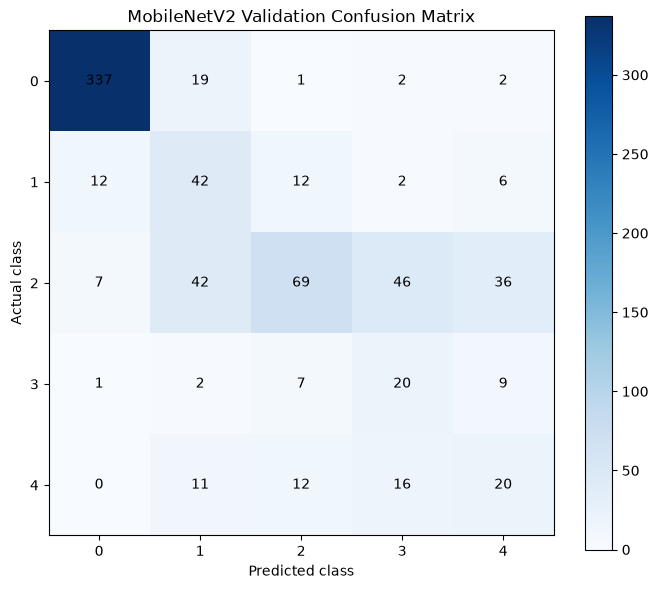

In [14]:
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("MobileNetV2 Validation Confusion Matrix")
ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center")
fig.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(RESULT_DIR / "mobilenetv2_confusion_matrix.png", dpi=200)
plt.show()

## 15. Save predictions and analyze errors

In [15]:
pred_df = val_df[["id_code", "diagnosis"]].copy()
pred_df.rename(columns={"diagnosis":"actual"}, inplace=True)
pred_df["predicted"] = y_pred
pred_df["confidence"] = confidence
for c in range(NUM_CLASSES):
    pred_df[f"prob_class_{c}"] = y_prob[:,c]
pred_df.to_csv(RESULT_DIR / "mobilenetv2_predictions.csv", index=False)

error_df = pred_df[pred_df.actual != pred_df.predicted].copy()
error_df = error_df.sort_values("confidence", ascending=False)
error_df.to_csv(RESULT_DIR / "mobilenetv2_errors.csv", index=False)
display(error_df.head(20))
print("Incorrect predictions:", len(error_df), "of", len(pred_df))

,id_code,actual,predicted,confidence,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4
496,e150935f66a6,2,0,0.976284,9.762844e-01,0.014048,0.006670,0.000376,0.002622
656,144a1a426137,2,0,0.976170,9.761701e-01,0.008199,0.009212,0.003727,0.002691
176,262ad704319c,4,3,0.972595,1.003545e-07,0.000015,0.004904,0.972595,0.022486
630,cb02bb47fdc5,0,1,0.969466,5.020103e-03,0.969466,0.019824,0.000682,0.005008
562,f066db7a2efe,0,1,0.966268,2.190589e-02,0.966268,0.008268,0.000200,0.003359
633,91cbe1c775ef,2,1,0.966254,4.607701e-03,0.966254,0.018262,0.007103,0.003774
6,44855f666225,2,3,0.963240,2.221850e-06,0.000286,0.011974,0.963240,0.024497
626,fc4d69128e7c,2,3,0.931313,5.680406e-03,0.011804,0.037339,0.931313,0.013864
691,38e0e28d35d3,1,0,0.929680,9.296798e-01,0.016051,0.030754,0.004258,0.019257
254,da6389d129aa,0,1,0.928596,5.211764e-03,0.928596,0.063229,0.000170,0.002794


Incorrect predictions: 245 of 733


## 16. Visualize misclassified images

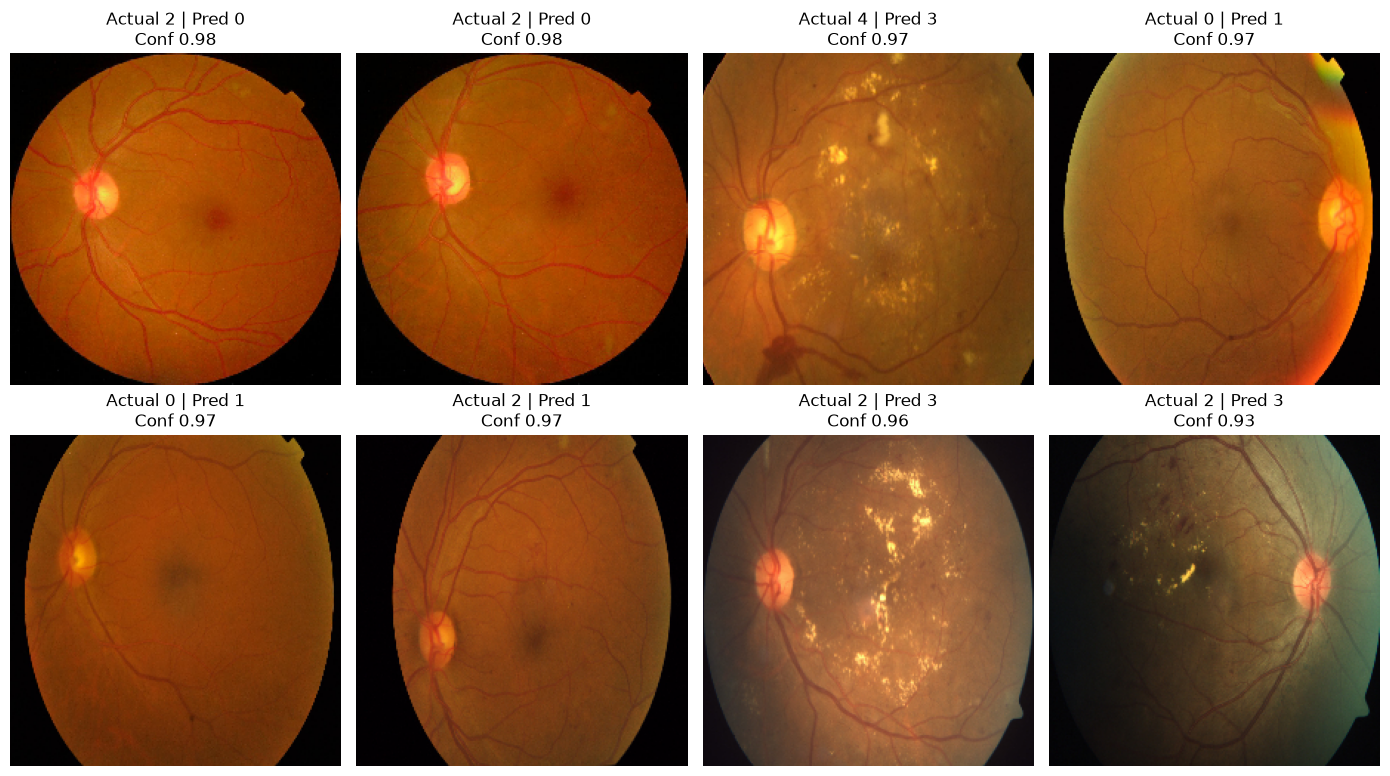

In [16]:
if error_df.empty:
    print("No incorrect validation predictions.")
else:
    plt.figure(figsize=(14,8))
    for i, (_, row) in enumerate(error_df.head(8).iterrows(), 1):
        img = tf.keras.utils.load_img(
            IMAGE_DIR / f"{row.id_code}.png", target_size=(IMG_SIZE, IMG_SIZE))
        plt.subplot(2,4,i); plt.imshow(img)
        plt.title(f"Actual {row.actual} | Pred {row.predicted}\nConf {row.confidence:.2f}")
        plt.axis("off")
    plt.tight_layout(); plt.show()

## 17. Model size and inference latency

In [17]:
model_size_mb = FINAL_MODEL_PATH.stat().st_size / (1024**2)
sample = next(iter(val_ds))[0][:1]
_ = model.predict(sample, verbose=0)  # warm-up
times = []
for _ in range(10):
    start = time.perf_counter()
    _ = model.predict(sample, verbose=0)
    times.append(time.perf_counter() - start)
latency_ms = float(np.mean(times) * 1000)
efficiency = {
    "model_size_mb": float(model_size_mb),
    "mean_single_image_inference_ms": latency_ms,
    "repeats": 10,
    "note": "Hardware-dependent measurement."
}
print(json.dumps(efficiency, indent=4))
with open(RESULT_DIR / "mobilenetv2_efficiency.json", "w") as f:
    json.dump(efficiency, f, indent=4)

{
    "model_size_mb": 22.893613815307617,
    "mean_single_image_inference_ms": 111.6130600004908,
    "repeats": 10,
    "note": "Hardware-dependent measurement."
}


## 18. Final summary and artifact check

In [18]:
print("MOBILENETV2 VALIDATION SUMMARY")
print("-" * 40)
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro precision: {precision_macro:.4f}")
print(f"Macro recall: {recall_macro:.4f}")
print(f"Macro F1: {f1_macro:.4f}")
print(f"QWK: {qwk:.4f}")
print(f"Model size: {model_size_mb:.2f} MB")
print(f"Inference latency: {latency_ms:.2f} ms/image")
print("\nSaved model:", FINAL_MODEL_PATH)
print("\nSaved MobileNetV2 results:")
for p in sorted(RESULT_DIR.glob("mobilenetv2_*")):
    print(p.name)

MOBILENETV2 VALIDATION SUMMARY
----------------------------------------
Accuracy: 0.6658
Macro precision: 0.4991
Macro recall: 0.5396
Macro F1: 0.4925
QWK: 0.7699
Model size: 22.89 MB
Inference latency: 111.61 ms/image

Saved model: S:\ISP\data\processed\models\mobilenetv2_final.keras

Saved MobileNetV2 results:
mobilenetv2_classification_report.csv
mobilenetv2_confusion_matrix.png
mobilenetv2_efficiency.json
mobilenetv2_errors.csv
mobilenetv2_finetuning_history.csv
mobilenetv2_predictions.csv
mobilenetv2_stage1_history.csv
mobilenetv2_validation_results.json


## Next phase — Hybrid model

Notebook 07 will use the same saved train/validation image IDs. MobileNetV2 uses 224×224 images and its own preprocessing; EfficientNetB3 uses 300×300 inputs and a different preprocessing convention. A hybrid network must preserve the correct preprocessing for each branch. Compare all models on the same validation images. Do not claim architectural novelty without a literature review.